In [2]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.notebook import tqdm

In [4]:
DATA_DIR = '/content/drive/MyDrive/ml-32m'

## 1. Load  and index data

In [5]:
ratings_df = pd.read_csv(os.path.join(DATA_DIR, 'ratings.csv'))
movies_df = pd.read_csv(os.path.join(DATA_DIR, 'movies.csv'))
print(len(ratings_df), 'ratings')
ratings_df.head()

32000204 ratings


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


In [6]:
index_to_user = sorted(ratings_df['userId'].unique())
index_to_item = sorted(ratings_df['movieId'].unique())
user_to_index = {user: i for i, user in enumerate(index_to_user)}
item_to_index = {item: i for i, item in enumerate(index_to_item)}

n_users = len(index_to_user)
n_items = len(index_to_item)

ratings_df['user_index'] = ratings_df['userId'].map(user_to_index)
ratings_df['item_index'] = ratings_df['movieId'].map(item_to_index)
print(n_users, 'users,', n_items, 'movies')

200948 users, 84432 movies


## 2. Train/test split by time

In [7]:
test_fraction = 0.1
is_test = np.zeros(len(ratings_df), dtype=bool)

for m, group in tqdm(ratings_df.groupby('user_index'), total=n_users):
  group = group.sort_values('timestamp')
  n_test = int(len(group) * test_fraction)
  if n_test > 0:
    newest_rows = group.index[-n_test:]
    is_test[newest_rows] = True

train_df = ratings_df[~is_test]
test_df = ratings_df[is_test]
print(len(train_df), 'train ratings,', len(test_df), 'test ratings')

  0%|          | 0/200948 [00:00<?, ?it/s]

28885713 train ratings, 3114491 test ratings


In [8]:
def to_lists(df, key, other, n):
  idx = [np.array([], dtype=int) for _ in range(n)]
  val = [np.array([], dtype=float) for _ in range(n)]
  for k, group in tqdm(df.groupby(key), total=df[key].nunique()):
    idx[k] = group[other].to_numpy()
    val[k] = group['rating'].to_numpy(dtype=float)
  return idx, val

user_items_train, user_ratings_train = to_lists(train_df, 'user_index', 'item_index', n_users)
user_items_test,  user_ratings_test  = to_lists(test_df,  'user_index', 'item_index', n_users)
item_users_train, item_ratings_train = to_lists(train_df, 'item_index', 'user_index', n_items)

  0%|          | 0/200948 [00:00<?, ?it/s]

  0%|          | 0/200948 [00:00<?, ?it/s]

  0%|          | 0/77535 [00:00<?, ?it/s]

## 3. ALS

In [9]:
def squared_error(user_items, user_ratings, U, V, user_biases, item_biases):
  se, count = 0.0, 0
  for m in range(len(user_items)):
    items, r = user_items[m], user_ratings[m]
    if len(items) == 0:
      continue
    pred = V[items] @ U[m] + user_biases[m] + item_biases[items]
    se += np.sum((r - pred) ** 2)
    count += len(items)
  return se, count

def loss_fn(user_items, user_ratings, U, V, user_biases, item_biases, lda, gamma, tau):
  se, _ = squared_error(user_items, user_ratings, U, V, user_biases, item_biases)
  reg_vectors = (tau / 2) * (np.sum(U ** 2) + np.sum(V ** 2))
  reg_biases = (gamma / 2) * (np.sum(user_biases ** 2) + np.sum(item_biases ** 2))
  return (lda / 2) * se + reg_vectors + reg_biases

def rmse(user_items, user_ratings, U, V, user_biases, item_biases):
  se, count = squared_error(user_items, user_ratings, U, V, user_biases, item_biases)
  return np.sqrt(se / count)

In [10]:
def update_users(user_items, user_ratings, U, V, user_biases, item_biases, lda, gamma, tau):
  K = U.shape[1]
  for m in range(len(user_items)):
    items, r = user_items[m], user_ratings[m]
    if len(items) == 0:
      continue
    Vm = V[items]
    # 1. bias first
    res = r - Vm @ U[m] - item_biases[items]
    user_biases[m] = lda * np.sum(res) / (lda * len(items) + gamma)
    # 2. then the vector
    A = lda * Vm.T @ Vm + tau * np.eye(K)
    b = lda * Vm.T @ (r - user_biases[m] - item_biases[items])
    U[m] = np.linalg.solve(A, b)

def update_items(item_users, item_ratings, U, V, user_biases, item_biases, lda, gamma, tau):
  K = V.shape[1]
  for n in range(len(item_users)):
    users, r = item_users[n], item_ratings[n]
    if len(users) == 0:
      continue
    Un = U[users]
    res = r - Un @ V[n] - user_biases[users]
    item_biases[n] = lda * np.sum(res) / (lda * len(users) + gamma)
    A = lda * Un.T @ Un + tau * np.eye(K)
    b = lda * Un.T @ (r - user_biases[users] - item_biases[n])
    V[n] = np.linalg.solve(A, b)

In [11]:
def train(user_items, user_ratings, item_users, item_ratings,
          K=10, lda=1.0, gamma=0.1, tau=5.0, iterations=10, seed=0, test=None):
  rng = np.random.default_rng(seed)
  U = rng.normal(0, 0.1, size=(len(user_items), K))
  V = rng.normal(0, 0.1, size=(len(item_users), K))
  user_biases = np.zeros(len(user_items))
  item_biases = np.zeros(len(item_users))

  losses, rmse_train, rmse_test = [], [], []
  for it in tqdm(range(iterations)):
    update_users(user_items, user_ratings, U, V, user_biases, item_biases, lda, gamma, tau)
    update_items(item_users, item_ratings, U, V, user_biases, item_biases, lda, gamma, tau)

    losses.append(loss_fn(user_items, user_ratings, U, V, user_biases, item_biases, lda, gamma, tau))
    rmse_train.append(rmse(user_items, user_ratings, U, V, user_biases, item_biases))
    if test is not None:
      rmse_test.append(rmse(test[0], test[1], U, V, user_biases, item_biases))

  return (U, V, user_biases, item_biases), losses, rmse_train, rmse_test

def plot(losses, train_rmse, test_rmse):
  plt.plot(losses, marker='o')
  plt.title('Negative log likelihood (train)')
  plt.xlabel('iteration'); plt.ylabel('loss')
  plt.show()

  plt.plot(train_rmse, label='train')
  plt.plot(test_rmse, label='test')
  plt.title('RMSE'); plt.xlabel('iteration'); plt.ylabel('RMSE')
  plt.legend(); plt.show()
  print(f"Final RMSE  train: {train_rmse[-1]:.4f}   test: {test_rmse[-1]:.4f}")

  0%|          | 0/10 [00:00<?, ?it/s]

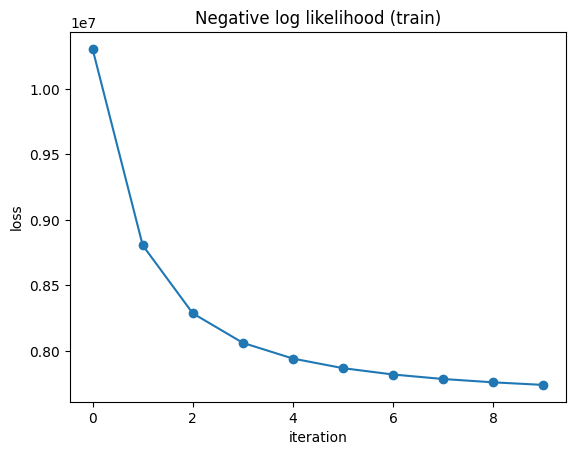

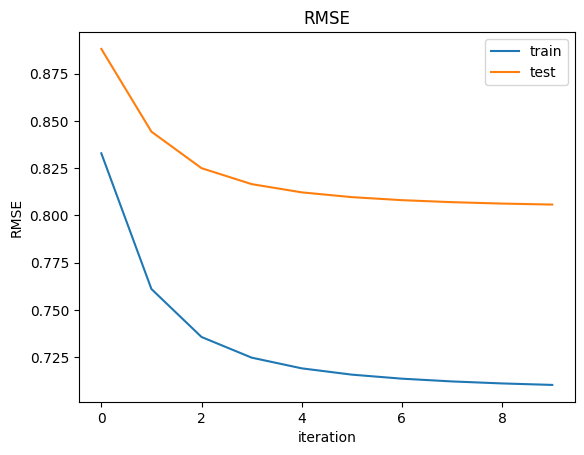

Final RMSE  train: 0.7103   test: 0.8058


In [12]:
train_data = (user_items_train, user_ratings_train, item_users_train, item_ratings_train)
test_data = (user_items_test, user_ratings_test)

model_10, losses_10, train_10, test_10 = train(*train_data, K=10, iterations=10, test=test_data)
plot(losses_10, train_10, test_10)

## 4. Overfitting: K = 10 vs K = 20

  0%|          | 0/10 [00:00<?, ?it/s]

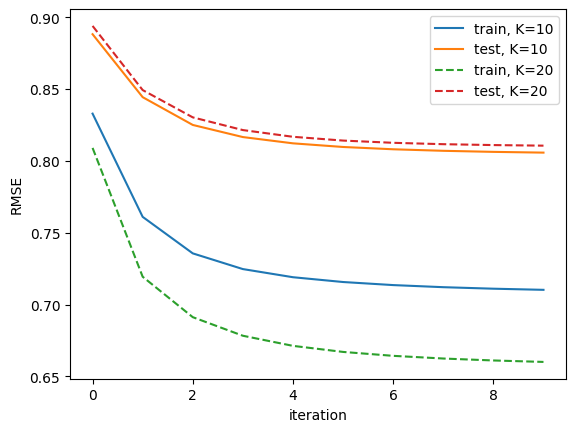

In [13]:
model_20, losses_20, train_20, test_20 = train(*train_data, K=20, iterations=10, test=test_data)

plt.plot(train_10, label='train, K=10')
plt.plot(test_10, label='test, K=10')
plt.plot(train_20, '--', label='train, K=20')
plt.plot(test_20, '--', label='test, K=20')
plt.xlabel('iteration'); plt.ylabel('RMSE'); plt.legend(); plt.show()

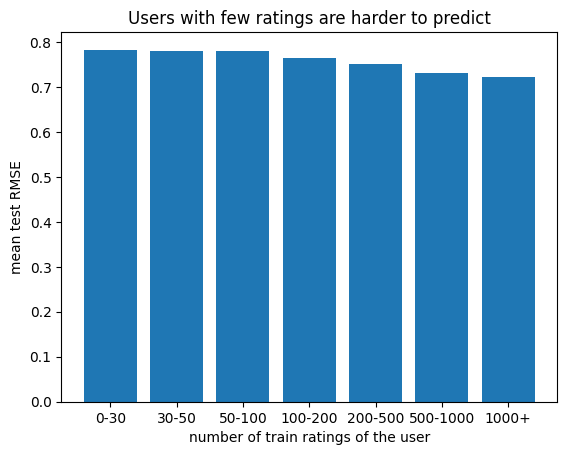

In [14]:
U, V, user_biases, item_biases = model_10

n_ratings = []      # number of train ratings of each user
user_error = []     # test RMSE of each user
for m in range(n_users):
  items, r = user_items_test[m], user_ratings_test[m]
  if len(items) == 0:
    continue
  pred = V[items] @ U[m] + user_biases[m] + item_biases[items]
  n_ratings.append(len(user_items_train[m]))
  user_error.append(np.sqrt(np.mean((r - pred) ** 2)))

n_ratings, user_error = np.array(n_ratings), np.array(user_error)
bins = [0, 30, 50, 100, 200, 500, 1000, 100000]
labels, values = [], []
for low, high in zip(bins[:-1], bins[1:]):
  mask = (n_ratings >= low) & (n_ratings < high)
  if mask.sum() > 0:
    labels.append(f'{low}-{high}' if high < 100000 else f'{low}+')
    values.append(user_error[mask].mean())

plt.bar(labels, values)
plt.xlabel('number of train ratings of the user'); plt.ylabel('mean test RMSE')
plt.title('Users with few ratings are harder to predict'); plt.show()

### Effect of τ

  0%|          | 0/5 [00:00<?, ?it/s]

tau = 0.5:  train 0.7156   test 0.8294


  0%|          | 0/5 [00:00<?, ?it/s]

tau = 5.0:  train 0.7191   test 0.8122


  0%|          | 0/5 [00:00<?, ?it/s]

tau = 50.0:  train 0.7473   test 0.8168


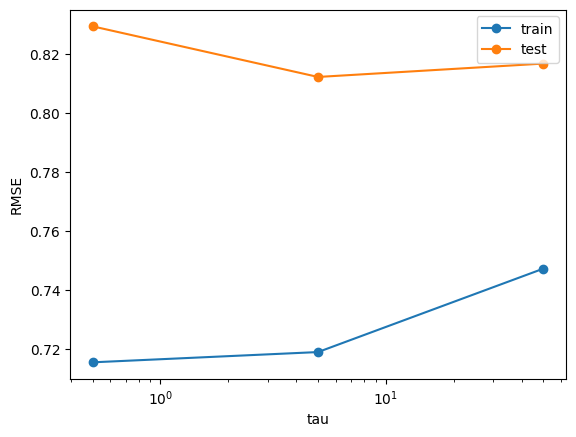

In [15]:
taus = [0.5, 5.0, 50.0]
final_train, final_test = [], []
for tau in taus:
  _, _, tr, te = train(*train_data, K=10, tau=tau, iterations=5, test=test_data)
  final_train.append(tr[-1]); final_test.append(te[-1])
  print(f'tau = {tau}:  train {tr[-1]:.4f}   test {te[-1]:.4f}')

plt.plot(taus, final_train, 'o-', label='train')
plt.plot(taus, final_test, 'o-', label='test')
plt.xscale('log'); plt.xlabel('tau'); plt.ylabel('RMSE'); plt.legend(); plt.show()

## 5. Train on all the ratings

  0%|          | 0/200948 [00:00<?, ?it/s]

  0%|          | 0/84432 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

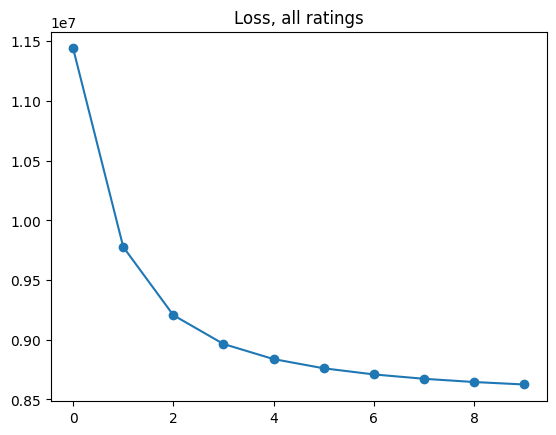

In [16]:
user_items_all, user_ratings_all = to_lists(ratings_df, 'user_index', 'item_index', n_users)
item_users_all, item_ratings_all = to_lists(ratings_df, 'item_index', 'user_index', n_items)

model_all, losses_all, train_all, _ = train(user_items_all, user_ratings_all, item_users_all, item_ratings_all,
                                            K=10, tau=5.0, iterations=10)
plt.plot(losses_all, marker='o'); plt.title('Loss, all ratings'); plt.show()
U, V, user_biases, item_biases = model_all

## 6. A new user who loves Lord of the Rings

In [17]:
lotr = movies_df[movies_df['title'].str.contains('Lord of the Rings')]
lotr = lotr[lotr['movieId'].isin(item_to_index)]
print(lotr[['movieId', 'title']])

my_items = np.array([item_to_index[i] for i in lotr['movieId']])
my_ratings = np.full(len(my_items), 5.0)

def new_user(items, r, V, item_biases, lda=1.0, gamma=0.1, tau=5.0, steps=10):
  K = V.shape[1]
  u, b = np.zeros(K), 0.0
  Vm = V[items]
  for _ in range(steps):
    b = lda * np.sum(r - Vm @ u - item_biases[items]) / (lda * len(items) + gamma)
    A = lda * Vm.T @ Vm + tau * np.eye(K)
    u = np.linalg.solve(A, lda * Vm.T @ (r - b - item_biases[items]))
  return u, b

u_new, b_new = new_user(my_items, my_ratings, V, item_biases)

       movieId                                              title
2026      2116                      Lord of the Rings, The (1978)
4888      4993  Lord of the Rings: The Fellowship of the Ring,...
5841      5952      Lord of the Rings: The Two Towers, The (2002)
7029      7153  Lord of the Rings: The Return of the King, The...
71797   231829  A Passage to Middle-earth: Making of 'Lord of ...
79743   267392  J.R.R. Tolkien and the Birth Of "The Lord of t...


In [18]:
n_ratings_per_movie = np.array([len(x) for x in item_users_all])
index_to_title = dict(zip(movies_df['movieId'], movies_df['title']))

def recommend(u, bias_weight=0.05, min_ratings=100, top=10):
  scores = V @ u + bias_weight * item_biases
  scores[my_items] = -np.inf                                   # don't recommend what the user rated
  if min_ratings > 0:
    scores[n_ratings_per_movie < min_ratings] = -np.inf        # remove rare movies
  best = np.argsort(-scores)[:top]
  for n in best:
    print(f'{scores[n]:6.2f}  {index_to_title[index_to_item[n]]}')

recommend(u_new)

  0.31  Stuart Saves His Family (1995)
  0.30  Heidi Fleiss: Hollywood Madam (1995)
  0.29  Bowfinger (1999)
  0.29  Pink Flamingos (1972)
  0.29  Brady Bunch Movie, The (1995)
  0.27  Hoop Dreams (1994)
  0.27  To Die For (1995)
  0.27  Tales from the Hood (1995)
  0.26  Election (1999)
  0.26  Nixon (1995)


In [19]:
print('--- full item bias (1.0) ---');        recommend(u_new, bias_weight=1.0)
print('--- no filter on rare movies ---');    recommend(u_new, min_ratings=0)

--- full item bias (1.0) ---
  0.85  Planet Earth (2006)
  0.85  Planet Earth II (2016)
  0.84  Twelve Angry Men (1954)
  0.77  Century of the Self, The (2002)
  0.75  Band of Brothers (2001)
  0.74  Civil War, The (1990)
  0.73  I, Claudius (1976)
  0.73  Powers of Ten (1977)
  0.72  The Rescue (2021)
  0.72  Godfather, The (1972)
--- no filter on rare movies ---
  0.31  Stuart Saves His Family (1995)
  0.30  Heidi Fleiss: Hollywood Madam (1995)
  0.29  Bowfinger (1999)
  0.29  Pink Flamingos (1972)
  0.29  Brady Bunch Movie, The (1995)
  0.27  Hoop Dreams (1994)
  0.27  To Die For (1995)
  0.27  Tales from the Hood (1995)
  0.26  Election (1999)
  0.26  Nixon (1995)


## 7. Polarising movies

In [20]:
lengths = np.array([np.linalg.norm(V[n]) for n in range(n_items)])
lengths[n_ratings_per_movie < 100] = np.nan     # only movies with enough ratings

order = np.argsort(-np.nan_to_num(lengths, nan=-1))
print('Most polarising:')
for n in order[:10]:
  print(f'{lengths[n]:5.2f}  {index_to_title[index_to_item[n]]}')

order = np.argsort(np.nan_to_num(lengths, nan=np.inf))
print('\nMost consensus:')
for n in order[:10]:
  print(f'{lengths[n]:5.2f}  {index_to_title[index_to_item[n]]}')

Most polarising:
 5.13  Dumb & Dumber (Dumb and Dumber) (1994)
 4.76  Star Wars: Episode II - Attack of the Clones (2002)
 4.66  Blair Witch Project, The (1999)
 4.54  Twilight Saga: Breaking Dawn - Part 2, The (2012)
 4.53  Twilight Saga: Eclipse, The (2010)
 4.50  Avengers: Infinity War - Part II (2019)
 4.50  Twilight (2008)
 4.46  Twilight Saga: Breaking Dawn - Part 1, The (2011)
 4.42  Twilight Saga: New Moon, The (2009)
 4.39  Star Wars: Episode III - Revenge of the Sith (2005)

Most consensus:
 0.37  Let's Make Love (1960)
 0.38  Goodbye, Columbus (1969)
 0.41  Miracle in Cell No. 7 (2013)
 0.41  Hammer, The (2007)
 0.42  Tell Me Who I Am (2019)
 0.45  Gaslight (1940)
 0.47  Deep Web (2015)
 0.47  Prince and the Showgirl, The (1957)
 0.48  Diggstown (1992)
 0.49  Black Sunday (1977)
